<a href="https://colab.research.google.com/github/2025csbindusb-rgb/DAV_LAB/blob/main/P10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

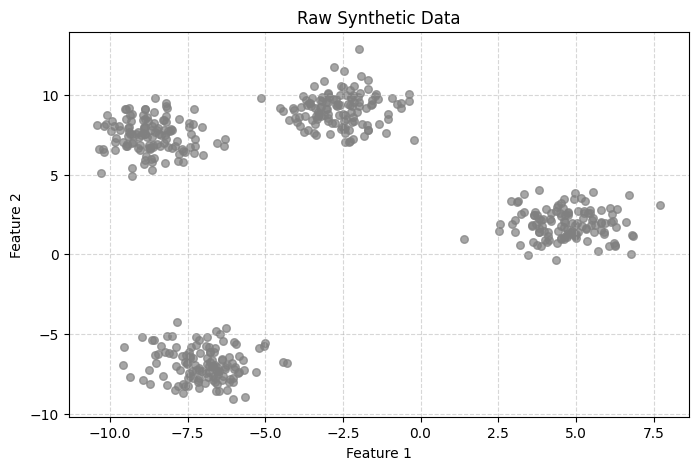

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate synthetic 2D data with 4 distinct clusters
X, y = make_blobs(n_samples=500, n_features=2, centers=4, cluster_std=1.0, random_state=42)

# Visualize the raw data
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=30, color='gray', alpha=0.7)
plt.title('Raw Synthetic Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

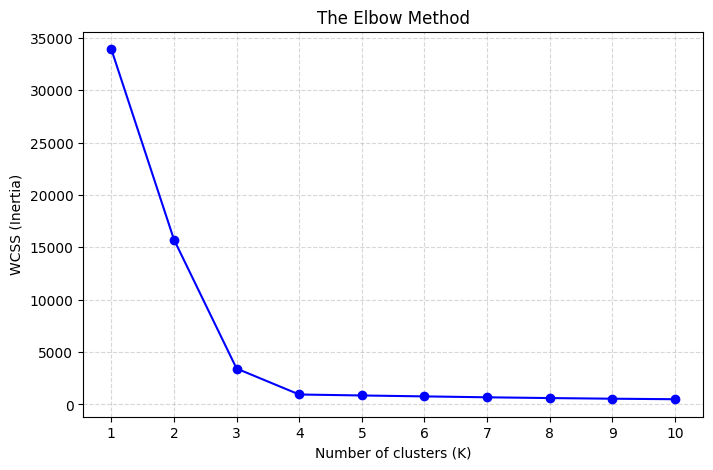

In [14]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

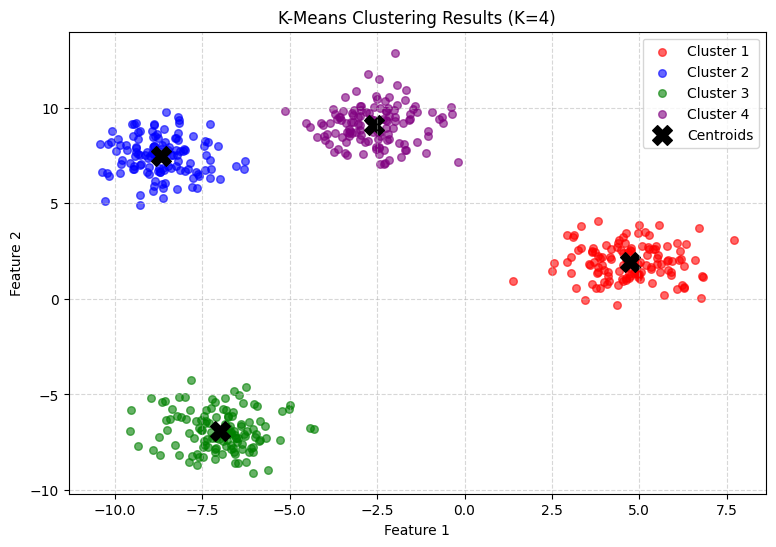

In [16]:
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

# Plotting the final clusters
plt.figure(figsize=(9, 6))
colors = ['red', 'blue', 'green', 'purple']

for i in range(optimal_k):
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], s=30, c=colors[i], label=f'Cluster {i+1}', alpha=0.6)

# Plot the centroids
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='black', marker='X', label='Centroids')

plt.title('K-Means Clustering Results (K=4)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()